https://miro.medium.com/v2/resize:fit:1400/0*cDRFtpTiOJFrfzS5.jpg

![House Price Prediction](https://miro.medium.com/v2/resize:fit:1400/0*cDRFtpTiOJFrfzS5.jpg)

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing

import os
import time
import warnings
import pickle

warnings.filterwarnings('ignore')

print("All Modules Loaded Successfully")

All Modules Loaded Successfully


# Step 1 Load Important Modules

# Step 2 Data Load

In [69]:
data = fetch_california_housing()

In [70]:
data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'feature_names', 'DESCR'])

In [71]:
df = pd.DataFrame(data.data,columns = data.feature_names)
df['MedHouseVal'] = data.target

In [72]:
data.target_names

['MedHouseVal']

In [73]:
df.sample(5)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
8657,5.5843,31.0,5.203240,1.073638,1647.0,2.425626,33.85,-118.38,3.84600
14516,2.8728,8.0,3.709150,1.046841,1742.0,1.897603,32.91,-117.12,1.14600
9015,6.7273,9.0,9.169519,1.299104,3029.0,2.468623,34.13,-118.68,5.00001
335,1.8438,35.0,4.623853,1.155963,323.0,2.963303,37.74,-122.18,0.90500
12818,3.4291,6.0,4.804158,1.065646,1982.0,2.168490,38.61,-121.49,1.05300


In [74]:
print(data['DESCR'])

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

    :Number of Instances: 20640

    :Number of Attributes: 8 numeric, predictive attributes and the target

    :Attribute Information:
        - MedInc        median income in block
        - HouseAge      median house age in block
        - AveRooms      average number of rooms
        - AveBedrms     average number of bedrooms
        - Population    block population
        - AveOccup      average house occupancy
        - Latitude      house block latitude
        - Longitude     house block longitude

    :Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
http://lib.stat.cmu.edu/datasets/

The target variable is the median house value for California districts.

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block group is the smallest geographical unit for which the U.S.
Census Bur

# Step 3 Exploratory Data Analysis

In [75]:
rows, col = df.shape
print('No of Rows:',rows)
print('No of Cols:', col)

No of Rows: 20640
No of Cols: 9


In [76]:
df.sample(5)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
10102,4.1321,35.0,5.376068,0.934473,989.0,2.817664,33.93,-117.97,1.981
18367,5.8596,37.0,6.793651,1.149912,1534.0,2.705467,37.18,-122.01,3.187
20478,5.6530,25.0,7.043388,1.018595,1699.0,3.510331,34.27,-118.73,2.258
18575,2.8348,8.0,3.781337,1.044568,2580.0,3.593315,36.91,-121.77,1.620
18555,3.5200,32.0,5.897297,1.097297,1122.0,3.032432,36.96,-122.03,2.842


In [77]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [78]:
df.tail()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847
20639,2.3886,16.0,5.254717,1.162264,1387.0,2.616981,39.37,-121.24,0.894


In [79]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [80]:
df.isna().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [81]:
# Missing Values : No

In [82]:
df.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')

In [83]:
len(df.columns)

9

In [84]:
plt.figure(figsize=(12,12))
for i in range(len(df.columns)):
    plt.subplot(3,3,i+1)
    plt.title(f'Distribution Analysis for {df.columns[i]}')
    plt.hist(df[df.columns[i]],color = 'r')
    
plt.show()

In [85]:
plt.figure(figsize=(10,10))
plt.title('Correletion b/w Features  ')
sns.heatmap(df.corr(),annot = True,cmap='mako')

<AxesSubplot:title={'center':'Correletion b/w Features  '}>

# step 4 Data Preprocessing

In [86]:
X  = df.iloc[:, :-2]
X

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85
...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43


In [87]:
y = df['MedHouseVal']
y

0        4.526
1        3.585
2        3.521
3        3.413
4        3.422
         ...  
20635    0.781
20636    0.771
20637    0.923
20638    0.847
20639    0.894
Name: MedHouseVal, Length: 20640, dtype: float64

In [88]:
# MIN_MAX_SCALER

In [89]:
scaler = MinMaxScaler()

In [90]:
scaled_X = scaler.fit_transform(X)

In [91]:

scaled_df = pd.DataFrame(scaled_X,columns=X.columns)

In [92]:
scaled_df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude
0,0.539668,0.784314,0.043512,0.020469,0.008941,0.001499,0.567481
1,0.538027,0.392157,0.038224,0.018929,0.067210,0.001141,0.565356
2,0.466028,1.000000,0.052756,0.021940,0.013818,0.001698,0.564293
3,0.354699,1.000000,0.035241,0.021929,0.015555,0.001493,0.564293
4,0.230776,1.000000,0.038534,0.022166,0.015752,0.001198,0.564293
...,...,...,...,...,...,...,...
20635,0.073130,0.470588,0.029769,0.023715,0.023599,0.001503,0.737513
20636,0.141853,0.333333,0.037344,0.029124,0.009894,0.001956,0.738576
20637,0.082764,0.313725,0.030904,0.023323,0.028140,0.001314,0.732200
20638,0.094295,0.333333,0.031783,0.024859,0.020684,0.001152,0.732200


In [93]:
scaled_df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,0.232464,0.541951,0.032488,0.022629,0.039869,0.001914,0.328572
std,0.131020,0.246776,0.017539,0.014049,0.031740,0.008358,0.226988
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.142308,0.333333,0.025482,0.019943,0.021974,0.001398,0.147715
50%,0.209301,0.549020,0.031071,0.021209,0.032596,0.001711,0.182784
75%,0.292641,0.705882,0.036907,0.022713,0.048264,0.002084,0.549416
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


# Step 5: Train Test Part Data Divide

In [94]:
X_train, X_test,y_train,y_test = train_test_split(scaled_X,y,test_size=0.1,random_state = 32)

In [95]:
X_train.shape

(18576, 7)

In [96]:
X_test.shape

(2064, 7)

In [97]:
y_train.shape

(18576,)

In [98]:



y_test.shape

(2064,)

# Step 6: Model Building ML

In [99]:
model = LinearRegression()

In [100]:
model.fit(X_train, y_train)

LinearRegression()

In [101]:
y_pred = model.predict(X_test)

In [102]:
compare_df = pd.DataFrame({'Actual Y' : y_test, 'Predicted Y' :y_pred})

In [103]:
compare_df

,Actual Y,Predicted Y
20038,0.52300,0.830969
17684,0.87500,1.171607
9720,2.53800,2.014867
17295,5.00001,4.142535
18736,0.98100,1.535928
...,...,...
12779,0.49800,0.990029
12771,0.67000,1.130043
15974,2.41900,2.563409
5100,1.42600,2.243695


# Step 7 : Model Evaluation

In [104]:
score = model.score(X_test,y_test)
print('Model Score:',score)

Model Score: 0.551362762499376


In [105]:
mae  = mean_absolute_error(y_test,y_pred)
print('Mean Absolute Error', mae)

Mean Absolute Error 0.5677843233572074


In [106]:
mse  = mean_squared_error(y_test,y_pred)
print('Mean squared Error', mae)

Mean squared Error 0.5677843233572074


In [107]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print('Root Mean Squared Error:', rmse)

Root Mean Squared Error: 0.7779707713343228


# step 8: Final Model Checking

In [108]:
matrix_dict = {
    'Model Number': [],
    'Model': [],
    'Model Score': [],
    'MAE': [],
    'MSE': [],
    'RMSE': []
}

for i in range(5000):

    X_train, X_test, y_train, y_test = train_test_split(
        scaled_X, y, test_size=0.1, random_state=i
    )
    model = LinearRegression()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    score = model.score(X_test, y_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)

    matrix_dict['Model Number'].append(i)
    matrix_dict['Model'].append(model)
    matrix_dict['Model Score'].append(score)
    matrix_dict['MAE'].append(mae)
    matrix_dict['MSE'].append(mse)
    matrix_dict['RMSE'].append(rmse)

    print(f'Checking Model {i+1}')

matrix_df = pd.DataFrame(matrix_dict)

print('Done')
    
    
    

Checking Model 1
Checking Model 2
Checking Model 3
Checking Model 4
Checking Model 5
Checking Model 6
Checking Model 7
Checking Model 8
Checking Model 9
Checking Model 10
Checking Model 11
Checking Model 12
Checking Model 13
Checking Model 14
Checking Model 15
Checking Model 16
Checking Model 17
Checking Model 18
Checking Model 19
Checking Model 20
Checking Model 21
Checking Model 22
Checking Model 23
Checking Model 24
Checking Model 25
Checking Model 26
Checking Model 27
Checking Model 28
Checking Model 29
Checking Model 30
Checking Model 31
Checking Model 32
Checking Model 33
Checking Model 34
Checking Model 35
Checking Model 36
Checking Model 37
Checking Model 38
Checking Model 39
Checking Model 40
Checking Model 41
Checking Model 42
Checking Model 43
Checking Model 44
Checking Model 45
Checking Model 46
Checking Model 47
Checking Model 48
Checking Model 49
Checking Model 50
Checking Model 51
Checking Model 52
Checking Model 53
Checking Model 54
Checking Model 55
Checking Model 56
C

Checking Model 444
Checking Model 445
Checking Model 446
Checking Model 447
Checking Model 448
Checking Model 449
Checking Model 450
Checking Model 451
Checking Model 452
Checking Model 453
Checking Model 454
Checking Model 455
Checking Model 456
Checking Model 457
Checking Model 458
Checking Model 459
Checking Model 460
Checking Model 461
Checking Model 462
Checking Model 463
Checking Model 464
Checking Model 465
Checking Model 466
Checking Model 467
Checking Model 468
Checking Model 469
Checking Model 470
Checking Model 471
Checking Model 472
Checking Model 473
Checking Model 474
Checking Model 475
Checking Model 476
Checking Model 477
Checking Model 478
Checking Model 479
Checking Model 480
Checking Model 481
Checking Model 482
Checking Model 483
Checking Model 484
Checking Model 485
Checking Model 486
Checking Model 487
Checking Model 488
Checking Model 489
Checking Model 490
Checking Model 491
Checking Model 492
Checking Model 493
Checking Model 494
Checking Model 495
Checking Mod

Checking Model 877
Checking Model 878
Checking Model 879
Checking Model 880
Checking Model 881
Checking Model 882
Checking Model 883
Checking Model 884
Checking Model 885
Checking Model 886
Checking Model 887
Checking Model 888
Checking Model 889
Checking Model 890
Checking Model 891
Checking Model 892
Checking Model 893
Checking Model 894
Checking Model 895
Checking Model 896
Checking Model 897
Checking Model 898
Checking Model 899
Checking Model 900
Checking Model 901
Checking Model 902
Checking Model 903
Checking Model 904
Checking Model 905
Checking Model 906
Checking Model 907
Checking Model 908
Checking Model 909
Checking Model 910
Checking Model 911
Checking Model 912
Checking Model 913
Checking Model 914
Checking Model 915
Checking Model 916
Checking Model 917
Checking Model 918
Checking Model 919
Checking Model 920
Checking Model 921
Checking Model 922
Checking Model 923
Checking Model 924
Checking Model 925
Checking Model 926
Checking Model 927
Checking Model 928
Checking Mod

Checking Model 1297
Checking Model 1298
Checking Model 1299
Checking Model 1300
Checking Model 1301
Checking Model 1302
Checking Model 1303
Checking Model 1304
Checking Model 1305
Checking Model 1306
Checking Model 1307
Checking Model 1308
Checking Model 1309
Checking Model 1310
Checking Model 1311
Checking Model 1312
Checking Model 1313
Checking Model 1314
Checking Model 1315
Checking Model 1316
Checking Model 1317
Checking Model 1318
Checking Model 1319
Checking Model 1320
Checking Model 1321
Checking Model 1322
Checking Model 1323
Checking Model 1324
Checking Model 1325
Checking Model 1326
Checking Model 1327
Checking Model 1328
Checking Model 1329
Checking Model 1330
Checking Model 1331
Checking Model 1332
Checking Model 1333
Checking Model 1334
Checking Model 1335
Checking Model 1336
Checking Model 1337
Checking Model 1338
Checking Model 1339
Checking Model 1340
Checking Model 1341
Checking Model 1342
Checking Model 1343
Checking Model 1344
Checking Model 1345
Checking Model 1346


Checking Model 1716
Checking Model 1717
Checking Model 1718
Checking Model 1719
Checking Model 1720
Checking Model 1721
Checking Model 1722
Checking Model 1723
Checking Model 1724
Checking Model 1725
Checking Model 1726
Checking Model 1727
Checking Model 1728
Checking Model 1729
Checking Model 1730
Checking Model 1731
Checking Model 1732
Checking Model 1733
Checking Model 1734
Checking Model 1735
Checking Model 1736
Checking Model 1737
Checking Model 1738
Checking Model 1739
Checking Model 1740
Checking Model 1741
Checking Model 1742
Checking Model 1743
Checking Model 1744
Checking Model 1745
Checking Model 1746
Checking Model 1747
Checking Model 1748
Checking Model 1749
Checking Model 1750
Checking Model 1751
Checking Model 1752
Checking Model 1753
Checking Model 1754
Checking Model 1755
Checking Model 1756
Checking Model 1757
Checking Model 1758
Checking Model 1759
Checking Model 1760
Checking Model 1761
Checking Model 1762
Checking Model 1763
Checking Model 1764
Checking Model 1765


Checking Model 2133
Checking Model 2134
Checking Model 2135
Checking Model 2136
Checking Model 2137
Checking Model 2138
Checking Model 2139
Checking Model 2140
Checking Model 2141
Checking Model 2142
Checking Model 2143
Checking Model 2144
Checking Model 2145
Checking Model 2146
Checking Model 2147
Checking Model 2148
Checking Model 2149
Checking Model 2150
Checking Model 2151
Checking Model 2152
Checking Model 2153
Checking Model 2154
Checking Model 2155
Checking Model 2156
Checking Model 2157
Checking Model 2158
Checking Model 2159
Checking Model 2160
Checking Model 2161
Checking Model 2162
Checking Model 2163
Checking Model 2164
Checking Model 2165
Checking Model 2166
Checking Model 2167
Checking Model 2168
Checking Model 2169
Checking Model 2170
Checking Model 2171
Checking Model 2172
Checking Model 2173
Checking Model 2174
Checking Model 2175
Checking Model 2176
Checking Model 2177
Checking Model 2178
Checking Model 2179
Checking Model 2180
Checking Model 2181
Checking Model 2182


... (2 outputs left out)

Checking Model 3387
Checking Model 3388
Checking Model 3389
Checking Model 3390
Checking Model 3391
Checking Model 3392
Checking Model 3393
Checking Model 3394
Checking Model 3395
Checking Model 3396
Checking Model 3397
Checking Model 3398
Checking Model 3399
Checking Model 3400
Checking Model 3401
Checking Model 3402
Checking Model 3403
Checking Model 3404
Checking Model 3405
Checking Model 3406
Checking Model 3407
Checking Model 3408
Checking Model 3409
Checking Model 3410
Checking Model 3411
Checking Model 3412
Checking Model 3413
Checking Model 3414
Checking Model 3415
Checking Model 3416
Checking Model 3417
Checking Model 3418
Checking Model 3419
Checking Model 3420
Checking Model 3421
Checking Model 3422
Checking Model 3423
Checking Model 3424
Checking Model 3425
Checking Model 3426
Checking Model 3427
Checking Model 3428
Checking Model 3429
Checking Model 3430
Checking Model 3431
Checking Model 3432
Checking Model 3433
Checking Model 3434
Checking Model 3435
Checking Model 3436


Checking Model 3808
Checking Model 3809
Checking Model 3810
Checking Model 3811
Checking Model 3812
Checking Model 3813
Checking Model 3814
Checking Model 3815
Checking Model 3816
Checking Model 3817
Checking Model 3818
Checking Model 3819
Checking Model 3820
Checking Model 3821
Checking Model 3822
Checking Model 3823
Checking Model 3824
Checking Model 3825
Checking Model 3826
Checking Model 3827
Checking Model 3828
Checking Model 3829
Checking Model 3830
Checking Model 3831
Checking Model 3832
Checking Model 3833
Checking Model 3834
Checking Model 3835
Checking Model 3836
Checking Model 3837
Checking Model 3838
Checking Model 3839
Checking Model 3840
Checking Model 3841
Checking Model 3842
Checking Model 3843
Checking Model 3844
Checking Model 3845
Checking Model 3846
Checking Model 3847
Checking Model 3848
Checking Model 3849
Checking Model 3850
Checking Model 3851
Checking Model 3852
Checking Model 3853
Checking Model 3854
Checking Model 3855
Checking Model 3856
Checking Model 3857


Checking Model 4220
Checking Model 4221
Checking Model 4222
Checking Model 4223
Checking Model 4224
Checking Model 4225
Checking Model 4226
Checking Model 4227
Checking Model 4228
Checking Model 4229
Checking Model 4230
Checking Model 4231
Checking Model 4232
Checking Model 4233
Checking Model 4234
Checking Model 4235
Checking Model 4236
Checking Model 4237
Checking Model 4238
Checking Model 4239
Checking Model 4240
Checking Model 4241
Checking Model 4242
Checking Model 4243
Checking Model 4244
Checking Model 4245
Checking Model 4246
Checking Model 4247
Checking Model 4248
Checking Model 4249
Checking Model 4250
Checking Model 4251
Checking Model 4252
Checking Model 4253
Checking Model 4254
Checking Model 4255
Checking Model 4256
Checking Model 4257
Checking Model 4258
Checking Model 4259
Checking Model 4260
Checking Model 4261
Checking Model 4262
Checking Model 4263
Checking Model 4264
Checking Model 4265
Checking Model 4266
Checking Model 4267
Checking Model 4268
Checking Model 4269


Checking Model 4633
Checking Model 4634
Checking Model 4635
Checking Model 4636
Checking Model 4637
Checking Model 4638
Checking Model 4639
Checking Model 4640
Checking Model 4641
Checking Model 4642
Checking Model 4643
Checking Model 4644
Checking Model 4645
Checking Model 4646
Checking Model 4647
Checking Model 4648
Checking Model 4649
Checking Model 4650
Checking Model 4651
Checking Model 4652
Checking Model 4653
Checking Model 4654
Checking Model 4655
Checking Model 4656
Checking Model 4657
Checking Model 4658
Checking Model 4659
Checking Model 4660
Checking Model 4661
Checking Model 4662
Checking Model 4663
Checking Model 4664
Checking Model 4665
Checking Model 4666
Checking Model 4667
Checking Model 4668
Checking Model 4669
Checking Model 4670
Checking Model 4671
Checking Model 4672
Checking Model 4673
Checking Model 4674
Checking Model 4675
Checking Model 4676
Checking Model 4677
Checking Model 4678
Checking Model 4679
Checking Model 4680
Checking Model 4681
Checking Model 4682


In [109]:
matrix_df

,Model Number,Model,Model Score,MAE,MSE,RMSE
0,0,LinearRegression(),0.539876,0.584250,0.632354,0.795207
1,1,LinearRegression(),0.539413,0.574266,0.619368,0.786999
2,2,LinearRegression(),0.502733,0.589630,0.668455,0.817591
3,3,LinearRegression(),0.568915,0.563485,0.580866,0.762146
4,4,LinearRegression(),0.533087,0.573290,0.587384,0.766410
...,...,...,...,...,...,...
4995,4995,LinearRegression(),0.500881,0.574729,0.642570,0.801605
4996,4996,LinearRegression(),0.500247,0.576966,0.693597,0.832825
4997,4997,LinearRegression(),0.505985,0.576654,0.662073,0.813678
4998,4998,LinearRegression(),0.517502,0.568705,0.611983,0.782293


In [110]:
matrix_df['Model Score'].max()

0.6053940148587416

In [111]:
matrix_df['Model Score'].min()

-17.627966718929788

In [112]:
final_model_df = matrix_df[matrix_df['Model Score'] == matrix_df['Model Score'].max()]

In [113]:
matrix_positive_df = matrix_df[matrix_df['Model Score']>=0.50]

In [117]:
plt.figure(figsize=(10, 5))

x = matrix_positive_df['Model Number'].values
y = matrix_positive_df['Model Score'].values * 100

plt.plot(x, y)

plt.title('All Model Score Comparison')
plt.xlabel('Model Number')
plt.ylabel('Model Score (%)')

plt.show()

# Step 9 : Final Model Save

In [118]:
final_model = final_model_df['Model']

In [119]:
with open('chatgpt_for_house.pkl','wb') as f:
    pickle.dump(final_model,f)
    print('Model Save Successfully!!!')

Model Save Successfully!!!


# Step 10 : Model Deployment

In [120]:
import os
print(os.getcwd())

C:\Users\Admin\Machine Learning Complete STP Project


In [121]:
import streamlit as st

In [122]:
st.spinner()

In [123]:
import pickle

with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print("Scaler Saved Successfully!")

Scaler Saved Successfully!


In [124]:
import pickle
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression

# Step 1: Select 8 Features
X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']

# Step 2: Create Scaler
scaler = MinMaxScaler()
scaled_X = scaler.fit_transform(X)

# Step 3: Train Model
chatgpt = LinearRegression()
chatgpt.fit(scaled_X, y)

# Step 4: Save Scaler
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# Step 5: Save Model
with open('chatgpt_for_house.pkl', 'wb') as f:
    pickle.dump(chatgpt, f)

print("Model and Scaler Saved Successfully!")
print("Total Features:", X.shape[1])

Model and Scaler Saved Successfully!
Total Features: 8


![My Screenshot](screenshot.png)
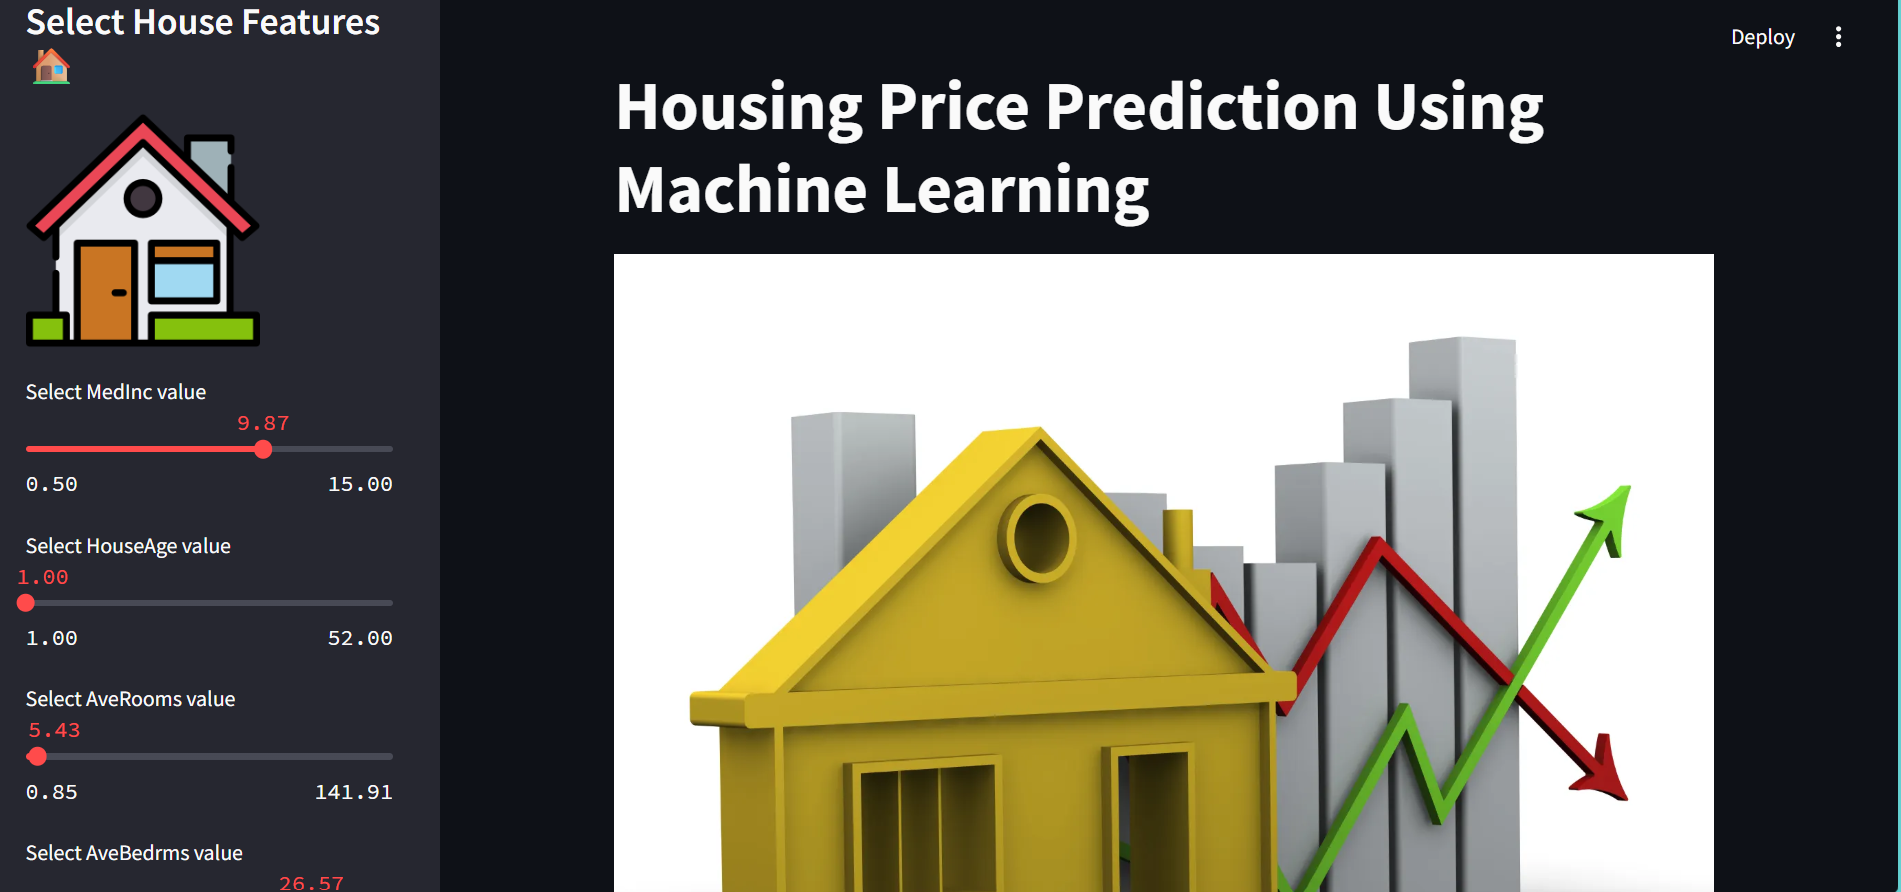